In [1]:
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

IMAGE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju0s2a9ekvms080138tjjpxr.jpg"
GT_POLYP_MASK_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju0s2a9ekvms080138tjjpxr.jpg"
MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/conference/claude/best_tf_dual_decoder_unet_v1.0.1.keras"

IMG_SIZE = (256, 256)

I0000 00:00:1787214913.868365   37478 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# --- rebuild architecture (needed to load this checkpoint, see last message) ---
def squeeze_and_excitation(x, ratio=16):
    f = x.shape[-1]
    s = tf.keras.layers.GlobalAveragePooling2D()(x)
    s = tf.keras.layers.Reshape((1, 1, f))(s)
    s = tf.keras.layers.Dense(f // ratio, activation="relu", use_bias=False)(s)
    s = tf.keras.layers.Dense(f, activation="sigmoid", use_bias=False)(s)
    return tf.keras.layers.Multiply()([x, s])

def _sp_shape(input_shape):
    return input_shape[:-1] + (1,)

def cbam_block(x, ratio=16):
    f = x.shape[-1]
    d1 = tf.keras.layers.Dense(f // ratio, activation="relu", use_bias=False)
    d2 = tf.keras.layers.Dense(f, use_bias=False)

    avg = tf.keras.layers.Reshape((1, 1, f))(tf.keras.layers.GlobalAveragePooling2D()(x))
    mx = tf.keras.layers.Reshape((1, 1, f))(tf.keras.layers.GlobalMaxPooling2D()(x))
    ch_att = tf.keras.layers.Activation("sigmoid")(
        tf.keras.layers.Add()([d2(d1(avg)), d2(d1(mx))])
    )
    x = tf.keras.layers.Multiply()([x, ch_att])

    avg_sp = tf.keras.layers.Lambda(lambda z: tf.reduce_mean(z, axis=-1, keepdims=True), output_shape=_sp_shape)(x)
    max_sp = tf.keras.layers.Lambda(lambda z: tf.reduce_max(z, axis=-1, keepdims=True), output_shape=_sp_shape)(x)
    concat = tf.keras.layers.Concatenate(axis=-1)([avg_sp, max_sp])
    sp_att = tf.keras.layers.Conv2D(1, 7, padding="same", activation="sigmoid", use_bias=False)(concat)
    return tf.keras.layers.Multiply()([x, sp_att])

def se_encoder_block(x, filters):
    x = tf.keras.layers.Conv2D(filters, 3, padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.Conv2D(filters, 3, padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = squeeze_and_excitation(x)
    return x, tf.keras.layers.MaxPooling2D((2, 2))(x)

def cbam_decoder_block(x, skip, filters):
    x = tf.keras.layers.Conv2DTranspose(filters, 2, strides=2, padding="same")(x)
    x = tf.keras.layers.Concatenate()([x, skip])
    x = tf.keras.layers.Conv2D(filters, 3, padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.Conv2D(filters, 3, padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    return cbam_block(x)

def build_dual_decoder_unet(input_shape=(256, 256, 3)):
    inputs = tf.keras.layers.Input(input_shape)
    s1, p1 = se_encoder_block(inputs, 64)
    s2, p2 = se_encoder_block(p1, 128)
    s3, p3 = se_encoder_block(p2, 256)
    s4, p4 = se_encoder_block(p3, 512)

    b1 = tf.keras.layers.Conv2D(1024, 3, padding="same")(p4)
    b1 = tf.keras.layers.BatchNormalization()(b1)
    b1 = tf.keras.layers.Activation("relu")(b1)
    b1 = tf.keras.layers.Conv2D(1024, 3, padding="same")(b1)
    b1 = tf.keras.layers.BatchNormalization()(b1)
    b1 = tf.keras.layers.Activation("relu")(b1)
    b1 = squeeze_and_excitation(b1)

    h = cbam_decoder_block(b1, s4, 512)
    h = cbam_decoder_block(h, s3, 256)
    h = cbam_decoder_block(h, s2, 128)
    h = cbam_decoder_block(h, s1, 64)
    healthy_output = tf.keras.layers.Conv2D(1, 1, padding="same", activation="sigmoid", name="healthy_output")(h)

    d = cbam_decoder_block(b1, s4, 512)
    d = cbam_decoder_block(d, s3, 256)
    d = cbam_decoder_block(d, s2, 128)
    d = cbam_decoder_block(d, s1, 64)
    polyp_output = tf.keras.layers.Conv2D(1, 1, padding="same", activation="sigmoid", name="polyp_output")(d)

    return tf.keras.models.Model(inputs, {"healthy_output": healthy_output, "polyp_output": polyp_output})

model = build_dual_decoder_unet()
model.load_weights(MODEL_PATH)

# --- warm-up: the FIRST predict() call triggers TF graph tracing/compilation,
# which is slow (several seconds to ~1 min). Doing it once here means every
# real predict() call afterwards (below, or on new images) is fast. ---
_ = model.predict(np.zeros((1, 256, 256, 3), dtype=np.float32), verbose=0)
print("Model ready.")

# --- OPTIONAL, run once: save a lightweight weights-only file so future
# notebook sessions load faster (skips re-parsing the full .keras archive).
# Uncomment the line below the first time, then switch back to
# model.load_weights(MODEL_PATH) above to MODEL_PATH = WEIGHTS_ONLY_PATH.
# WEIGHTS_ONLY_PATH = MODEL_PATH.replace(".keras", ".weights.h5")
# model.save_weights(WEIGHTS_ONLY_PATH)

W0000 00:00:1787214983.211879   37478 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1787214983.212177   37478 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1949 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9
I0000 00:00:1787215115.206660   38902 service.cc:153] XLA service 0x7287540504a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1787215115.206714   38902 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 12.7.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1787215115.298383   38902 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1787215115.994889   38902 cuda

Model ready.


In [3]:
# --- preprocessing (same as training: resize, CLAHE, sharpen, gaussian) ---
def apply_clahe(img):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2RGB)

def apply_sharpen(img):
    k = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
    return cv2.filter2D(img, -1, k)


def show_segmentation(image_path, gt_mask_path=None, img_size=IMG_SIZE):
    """Runs the model on one image and displays input / GT mask (optional) /
    predicted polyp mask / predicted healthy mask, side by side."""
    img = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, img_size, interpolation=cv2.INTER_AREA)

    proc = cv2.GaussianBlur(apply_sharpen(apply_clahe(img)), (3, 3), 0)
    model_input = np.expand_dims(proc.astype(np.float32) / 255.0, axis=0)

    preds = model.predict(model_input, verbose=0)
    healthy_pred = preds["healthy_output"][0, ..., 0]
    polyp_pred = preds["polyp_output"][0, ..., 0]

    gt_mask = None
    if gt_mask_path:
        gt_mask = cv2.imread(gt_mask_path, cv2.IMREAD_GRAYSCALE)
        gt_mask = cv2.resize(gt_mask, img_size, interpolation=cv2.INTER_NEAREST)

    n = 4 if gt_mask is not None else 3
    fig, axes = plt.subplots(1, n, figsize=(4.5 * n, 5))

    axes[0].imshow(img)
    axes[0].set_title("Input image")
    axes[0].axis("off")

    i = 1
    if gt_mask is not None:
        axes[i].imshow(gt_mask, cmap="gray")
        axes[i].set_title("Ground truth polyp mask")
        axes[i].axis("off")
        i += 1

    axes[i].imshow(polyp_pred, cmap="Reds")
    axes[i].set_title("Predicted polyp mask")
    axes[i].axis("off")
    i += 1

    axes[i].imshow(healthy_pred, cmap="Greens")
    axes[i].set_title("Predicted healthy mask")
    axes[i].axis("off")

    plt.tight_layout()
    plt.show()

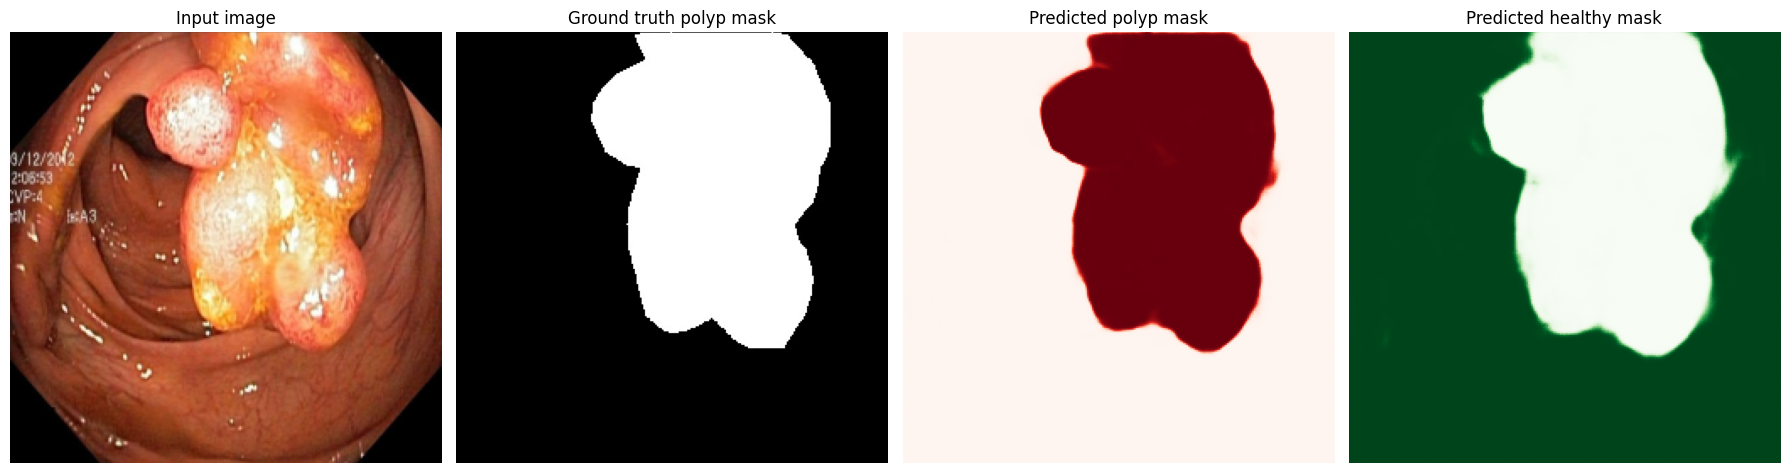

In [4]:
show_segmentation(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju2r6mt2om21099352pny5gw.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju2r6mt2om21099352pny5gw.jpg",
)

In [5]:
# --- Grad-CAM for segmentation (Seg-Grad-CAM: target = sum of predicted mask) ---
def make_gradcam_heatmap(model, model_input, branch="polyp_output"):
    """branch: 'polyp_output' or 'healthy_output'.
    Targets the last decoder feature map (right before the final 1x1 conv)."""
    target_layer_output = model.get_layer(branch).input
    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[target_layer_output, model.get_layer(branch).output],
    )

    with tf.GradientTape() as tape:
        conv_output, preds = grad_model(model_input)
        target_score = tf.reduce_sum(preds)  # scalar: total predicted mask "activation"

    grads = tape.gradient(target_score, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))  # (channels,)

    conv_output = conv_output[0]  # drop batch dim -> (H, W, C)
    heatmap = tf.reduce_sum(conv_output * pooled_grads, axis=-1)
    heatmap = tf.nn.relu(heatmap)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def overlay_heatmap(base_img_float, heatmap, img_size=IMG_SIZE, alpha=0.45):
    """base_img_float: HxWx3 in [0,1]. heatmap: small HxW in [0,1]."""
    heatmap_resized = cv2.resize(heatmap, img_size)
    heatmap_color = plt.cm.jet(heatmap_resized)[..., :3]  # RGB in [0,1]
    return np.clip((1 - alpha) * base_img_float + alpha * heatmap_color, 0, 1)


def show_gradcam(image_path, gt_mask_path=None, branch="polyp_output"):
    img = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)

    proc = cv2.GaussianBlur(apply_sharpen(apply_clahe(img)), (3, 3), 0)
    model_input = tf.convert_to_tensor(
        np.expand_dims(proc.astype(np.float32) / 255.0, axis=0)
    )

    preds = model.predict(model_input, verbose=0)
    polyp_pred = preds["polyp_output"][0, ..., 0]
    healthy_pred = preds["healthy_output"][0, ..., 0]

    gt_mask = None
    if gt_mask_path:
        gt_mask = cv2.imread(gt_mask_path, cv2.IMREAD_GRAYSCALE)
        gt_mask = cv2.resize(gt_mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

    heatmap = make_gradcam_heatmap(model, model_input, branch=branch)

    # Overlay uses ONLY the polyp mask (coral), regardless of `branch`
    polyp_mask_bin = (polyp_pred > 0.5).astype(np.float32)[..., None]
    polyp_color = np.array([231, 76, 60]) / 255.0
    overlay = np.clip(
        img.astype(np.float32) / 255.0 * (1 - 0.45 * polyp_mask_bin)
        + polyp_color * 0.45 * polyp_mask_bin,
        0, 1,
    )

    n = 6 if gt_mask is not None else 5
    fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 5))

    axes[0].imshow(img)
    axes[0].set_title("Input image")
    axes[0].axis("off")

    i = 1
    if gt_mask is not None:
        axes[i].imshow(gt_mask, cmap="gray")
        axes[i].set_title("Ground truth polyp mask")
        axes[i].axis("off")
        i += 1

    axes[i].imshow(polyp_pred, cmap="Reds")
    axes[i].set_title("Predicted polyp mask")
    axes[i].axis("off")
    i += 1

    axes[i].imshow(healthy_pred, cmap="Greens")
    axes[i].set_title("Predicted healthy mask")
    axes[i].axis("off")
    i += 1

    axes[i].imshow(heatmap, cmap="jet")
    axes[i].set_title(f"Grad-CAM heatmap ({branch})")
    axes[i].axis("off")
    i += 1

    axes[i].imshow(overlay)
    axes[i].set_title("Overlay (polyp only)")
    axes[i].axis("off")

    plt.tight_layout()
    plt.show()

W0000 00:00:1787215283.471715   37478 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 4.09GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
W0000 00:00:1787215283.645869   37478 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 4.10GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
W0000 00:00:1787215283.808666   37478 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 4.16GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
W0000 00:00:1787215283.954991   37478 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 4.31GiB with freed_by_c

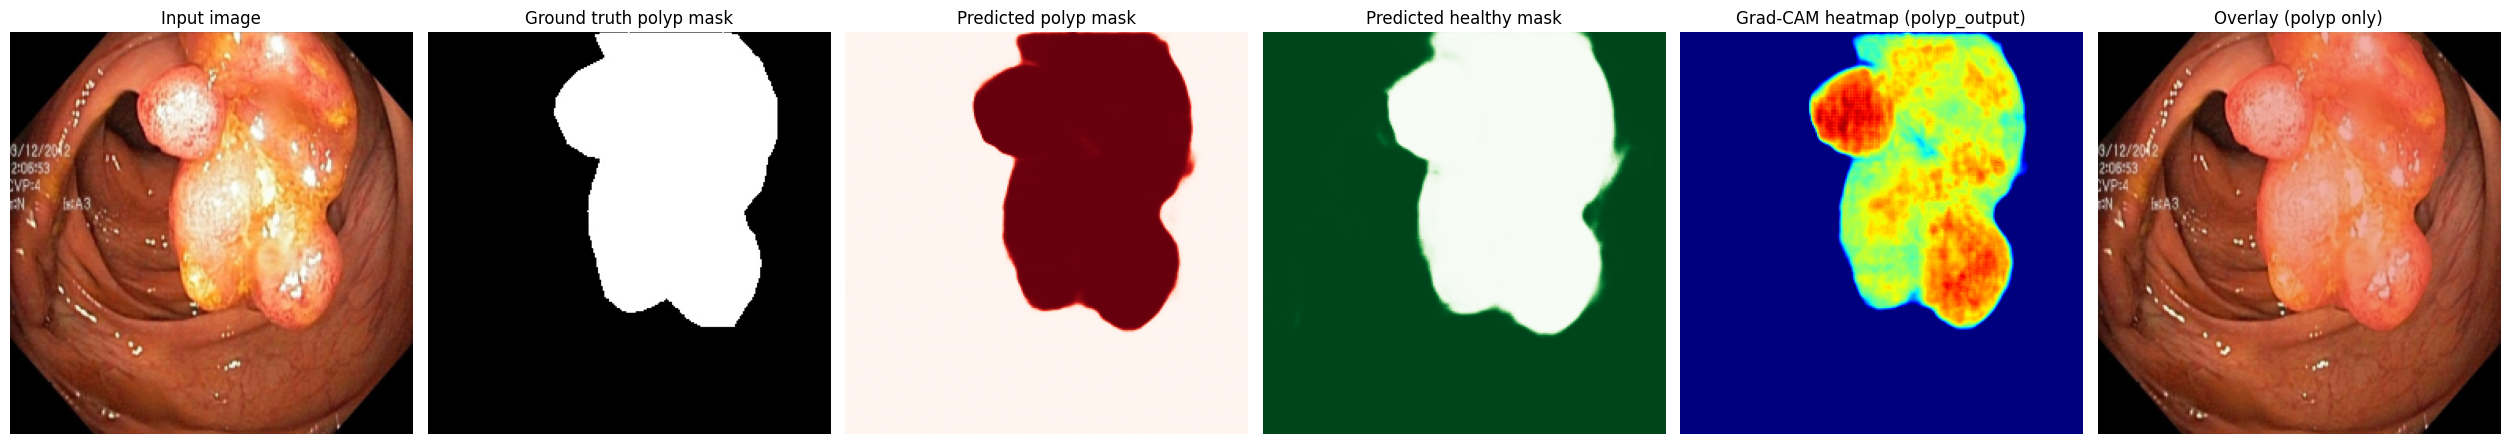

In [6]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju2r6mt2om21099352pny5gw.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju2r6mt2om21099352pny5gw.jpg",
    branch="polyp_output",
)

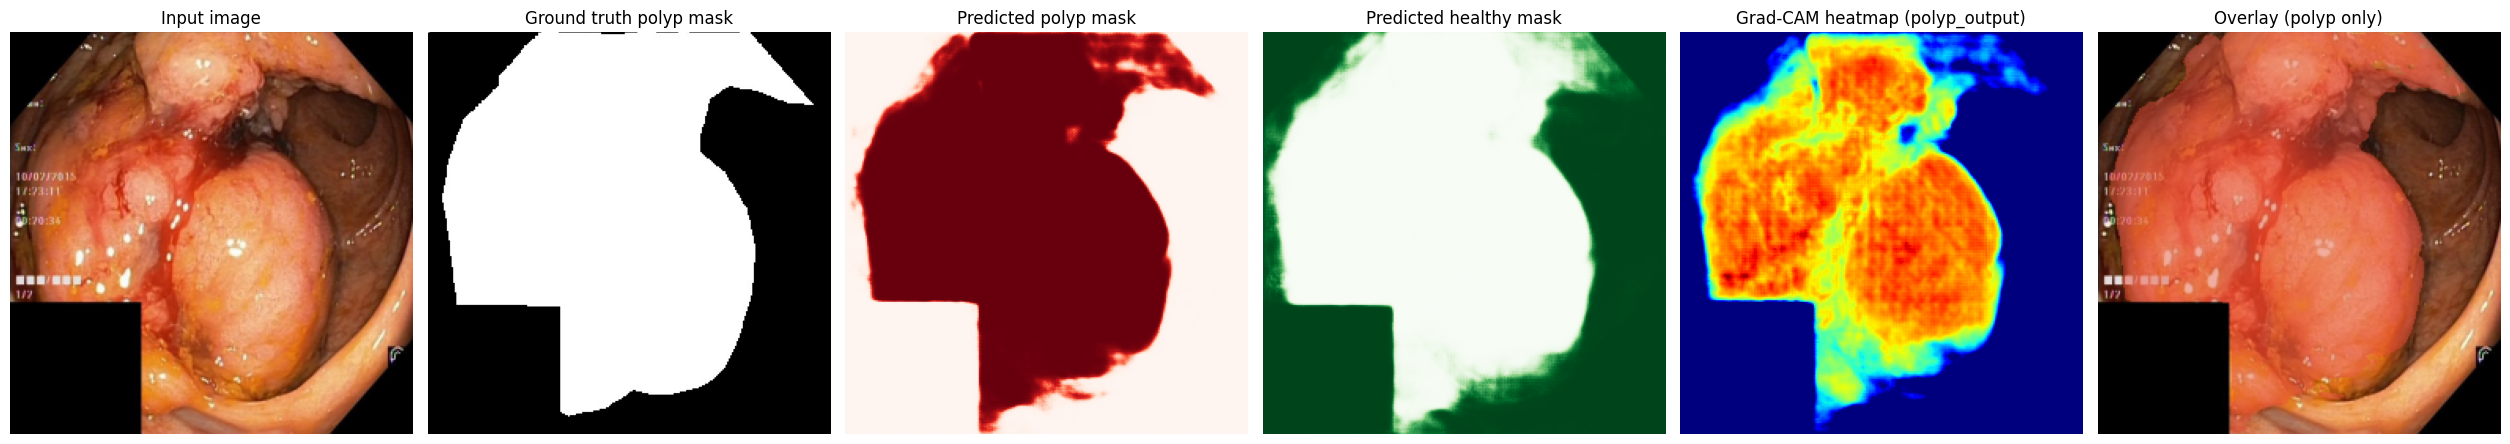

In [7]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju32phw2bv130801yj7bkouq.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju32phw2bv130801yj7bkouq.jpg",
    branch="polyp_output",
)

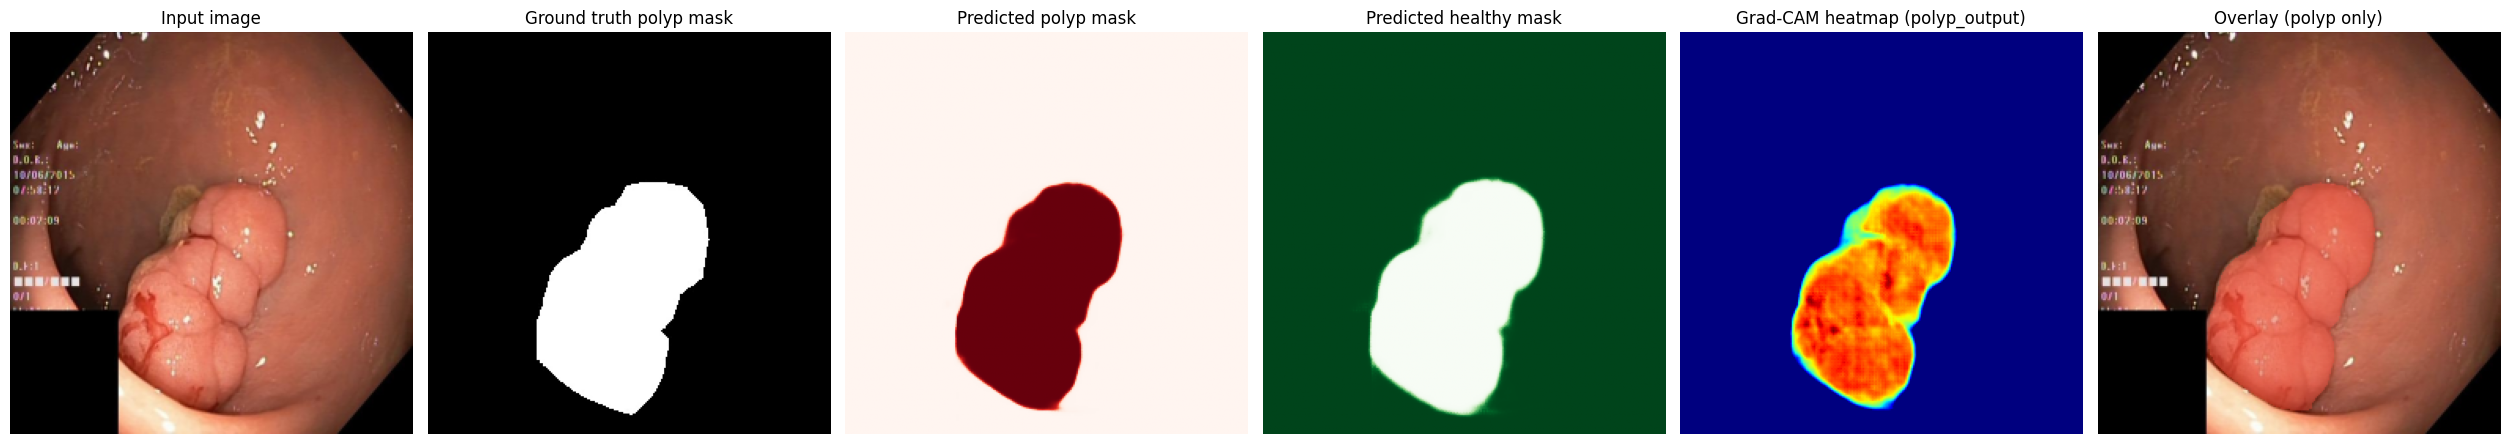

In [8]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju42dwedlmk60871jbgu4ehi.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju42dwedlmk60871jbgu4ehi.jpg",
    branch="polyp_output",
)

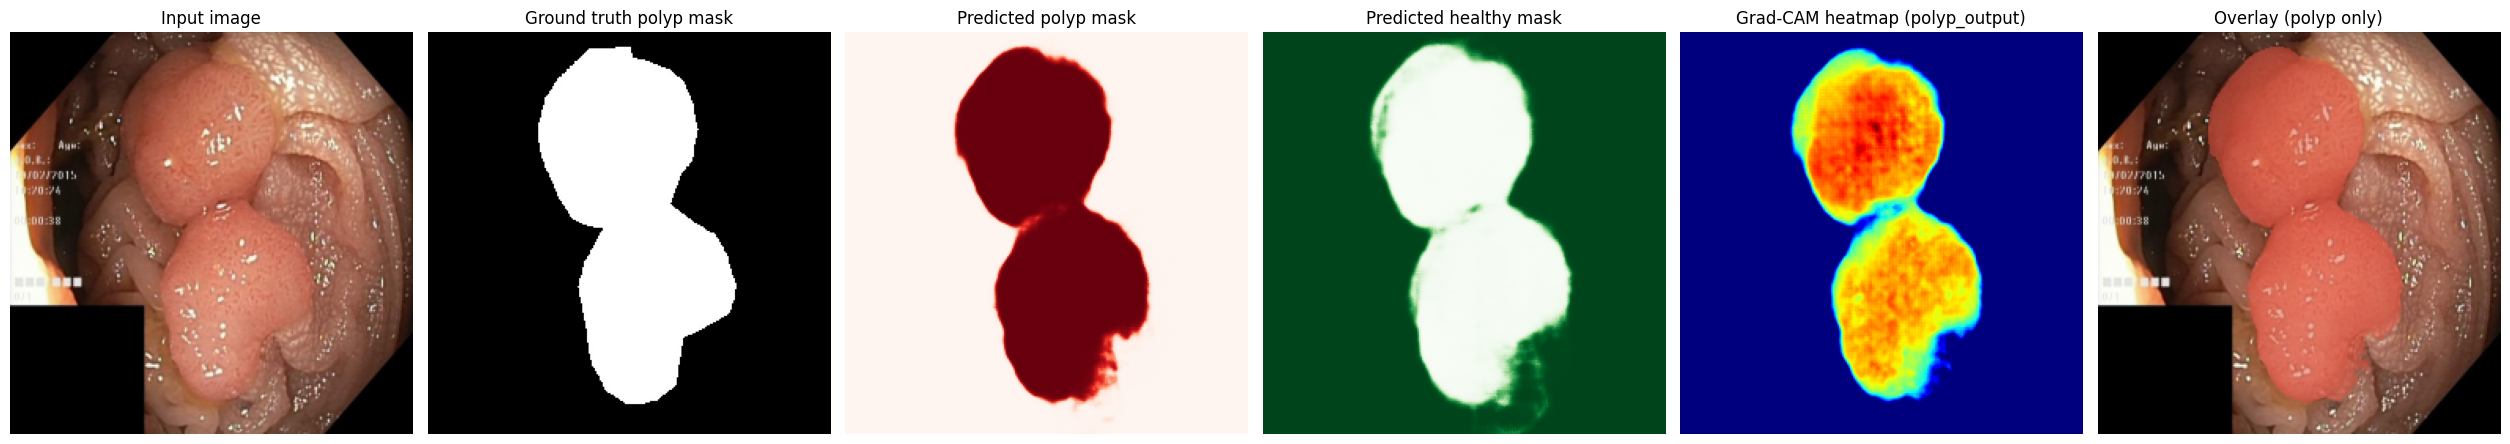

In [9]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju34aozyyy830993bn16u32n.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju34aozyyy830993bn16u32n.jpg",
    branch="polyp_output",
)

In [ ]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju34i3qvcyog0855qiejxx5w.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju34i3qvcyog0855qiejxx5w.jpg",
    branch="polyp_output",
)